# ORL Face Recognition

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Distinguish identities from a small academic face image dataset.

**Approach:** OpenCV image preprocessing and traditional classification.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Classification </span>
    </span>
    </center>
<br>
<h1>By GUERBOUZ MOHAMMED ALAA EDDINE</h1>

## Importing Libraries
The notebook begins by importing necessary libraries:
- **os**: For interacting with the operating system (e.g., file paths).
- **cv2**: OpenCV for image processing.
- **numpy**: For numerical operations.
- **sklearn.model_selection.train_test_split**: For splitting datasets into training and testing sets.
- **sklearn.metrics.classification_report, confusion_matrix**: For evaluating the model's performance.
- **sklearn.neighbors.KNeighborsClassifier**: For implementing the k-NN classifier.
- **sklearn.decomposition.PCA**: For Principal Component Analysis (PCA) to reduce dimensionality.
- **matplotlib.pyplot**: For plotting and visualizing data.

In [1]:
import os
import cv2
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

## Loading the Dataset
The `load_orl_dataset` function is defined to load the ORL dataset:
- **Input**: Path to the dataset.
- **Output**: A tuple containing images and their corresponding labels.
- **Process**: The function iterates through directories, reads images in grayscale, and assigns labels based on folder names.

In [2]:
# Function to load the dataset
def load_orl_dataset(dataset_path):
    images, labels = [], []
    label_map = {}  
    current_label = 0  

    for person_dir in sorted(os.listdir(dataset_path)): 
        person_path = os.path.join(dataset_path, person_dir)
        if os.path.isdir(person_path):
            # Map folder name to a numeric label
            if person_dir not in label_map:
                label_map[person_dir] = current_label
                current_label += 1

            for image_name in os.listdir(person_path):
                image_path = os.path.join(person_path, image_name)
                image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
                if image is not None:
                    images.append(image)
                    labels.append(label_map[person_dir])
    return np.array(images), np.array(labels)


## Preprocessing Images
The `preprocess_images` function preprocesses the images:
- **Input**: List of images and desired size (default is 64x64).
- **Output**: A numpy array of flattened images.
- **Process**: Resizes images to the specified size and flattens them into 1D arrays.

In [3]:
# Function to preprocess images
def preprocess_images(images, size=(64, 64)):
    processed_images = []
    for img in images:
        resized_img = cv2.resize(img, size)
        flattened_img = resized_img.flatten()  # Convert 2D to 1D
        processed_images.append(flattened_img)
    return np.array(processed_images)


## Testing with an External Image
The `test_with_external_image` function tests the classifier with an external image:
- **Input**: Path to the external image, classifier, PCA object (optional), and size.
- **Output**: Predicted label for the external image.
- **Process**: Reads the image, resizes it, flattens it, applies PCA (if provided), and predicts the label.

In [4]:
# Function to test with an external image
def test_with_external_image(image_path, classifier, pca=None, size=(64, 64)):
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    img_resized = cv2.resize(img, size).flatten()
    if pca:
        img_resized = pca.transform([img_resized])
    prediction = classifier.predict(img_resized)
    return prediction


## Plotting Results
The `plot_results` function plots the classification results:
- **Input**: Images, true labels, and predicted labels.
- **Output**: A 3x3 grid of images with their true and predicted labels.
- **Process**: Uses `matplotlib` to display the images along with their labels.

In [5]:
# Function to plot results
def plot_results(images, labels, predictions):
    plt.figure(figsize=(10, 10))
    for i in range(9):  # Plot 9 images
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].reshape(64, 64), cmap='gray')
        plt.title(f"True: {labels[i]} | Pred: {predictions[i]}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()


## Main Execution
The main execution block performs the following steps:
1. **Load the dataset**: Loads images and labels using `load_orl_dataset`.
2. **Preprocess images**: Converts images to the required format using `preprocess_images`.
3. **Split dataset**: Splits the dataset into training and testing sets using `train_test_split`.
4. **Apply PCA**: Reduces dimensionality using PCA.
5. **Train k-NN classifier**: Fits the k-NN classifier on the training data.
6. **Predict labels**: Predicts labels for the test set.
7. **Print classification report**: Evaluates the model's performance using `classification_report`.

In [6]:

# Main execution
if __name__ == "__main__":
    
    dataset_path = r"data"

  
    images, labels = load_orl_dataset(dataset_path)
    print(f"Loaded {len(images)} images from {len(set(labels))} classes.")


    processed_images = preprocess_images(images)

   
    X_train, X_test, y_train, y_test = train_test_split(processed_images, labels, test_size=0.2, random_state=42)

  
    pca = PCA(n_components=40)  
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

   
    knn = KNeighborsClassifier(n_neighbors=3)
    knn.fit(X_train_pca, y_train)

   
    y_pred = knn.predict(X_test_pca)
    print("Classification Report:")
    print(classification_report(y_test, y_pred))


Loaded 400 images from 40 classes.
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         1
           2       1.00      0.50      0.67         2
           3       1.00      1.00      1.00         4
           4       1.00      1.00      1.00         3
           5       1.00      1.00      1.00         3
           6       0.00      0.00      0.00         0
           7       1.00      0.67      0.80         6
           8       1.00      1.00      1.00         2
           9       1.00      1.00      1.00         2
          10       0.67      1.00      0.80         2
          11       1.00      1.00      1.00         3
          12       0.00      0.00      0.00         2
          13       0.33      1.00      0.50         1
          14       1.00      1.00      1.00         3
          15       0.00      0.00      0.00         2
          17       0.75

C:\Users\Dingue\newEnvirment\NEW-VENV\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Dingue\newEnvirment\NEW-VENV\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\Dingue\newEnvirment\NEW-VENV\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\

## Evaluation Metrics
The notebook also includes code to calculate additional evaluation metrics:
- **F1-score**: Measures the model's accuracy using the `f1_score` function.
- **Sensitivity (Recall)**: Measures the true positive rate using `recall_score`.
- **Specificity**: Measures the true negative rate (not well-defined for multi-class classification).
- **R-statistic (Correlation coefficient)**: Measures the correlation between true and predicted labels using `np.corrcoef`.
- **Confusion Matrix**: Displays the confusion matrix using `confusion_matrix`.

In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
import numpy as np
# Assuming you have already trained your k-NN model and made predictions
# y_test: True labels
# y_pred: Predicted labels from the k-NN model
# Calculate F-measure (F1-score)
f_measure = f1_score(y_test, y_pred, average='weighted')  # Use 'weighted' for multi-class classification
print(f"F-measure (F1-score): {f_measure:.4f}")


F-measure (F1-score): 0.8838


In [8]:
# Calculate Specificity and Sensitivity from the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
# Sensitivity (Recall) = TP / (TP + FN)
sensitivity = recall_score(y_test, y_pred, average='weighted')  # Use 'weighted' for multi-class
print(f"Sensitivity (Recall): {sensitivity:.4f}")


Sensitivity (Recall): 0.8875


C:\Users\Dingue\newEnvirment\NEW-VENV\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [9]:
# Specificity = TN / (TN + FP)
# For multi-class, calculate specificity for each class and average
specificity = np.mean([conf_matrix[i, i] / np.sum(conf_matrix[i, :]) for i in range(len(np.unique(y_test)))])
print(f"Specificity: {specificity:.4f}")


Specificity: nan


C:\Users\Dingue\AppData\Local\Temp\ipykernel_21196\4121503120.py:3: RuntimeWarning: invalid value encountered in scalar divide
  specificity = np.mean([conf_matrix[i, i] / np.sum(conf_matrix[i, :]) for i in range(len(np.unique(y_test)))])


In [10]:
# Calculate R-statistic (Correlation coefficient)
# Use numpy to calculate the correlation between true and predicted labels
r_statistic = np.corrcoef(y_test, y_pred)[0, 1]
print(f"R-statistic (Correlation coefficient): {r_statistic:.4f}")

R-statistic (Correlation coefficient): 0.9881


In [11]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Confusion Matrix:
[[3 0 0 ... 0 0 0]
 [0 1 0 ... 0 0 0]
 [0 0 1 ... 0 0 0]
 ...
 [0 0 0 ... 2 0 0]
 [0 0 0 ... 0 4 0]
 [0 0 0 ... 0 0 4]]


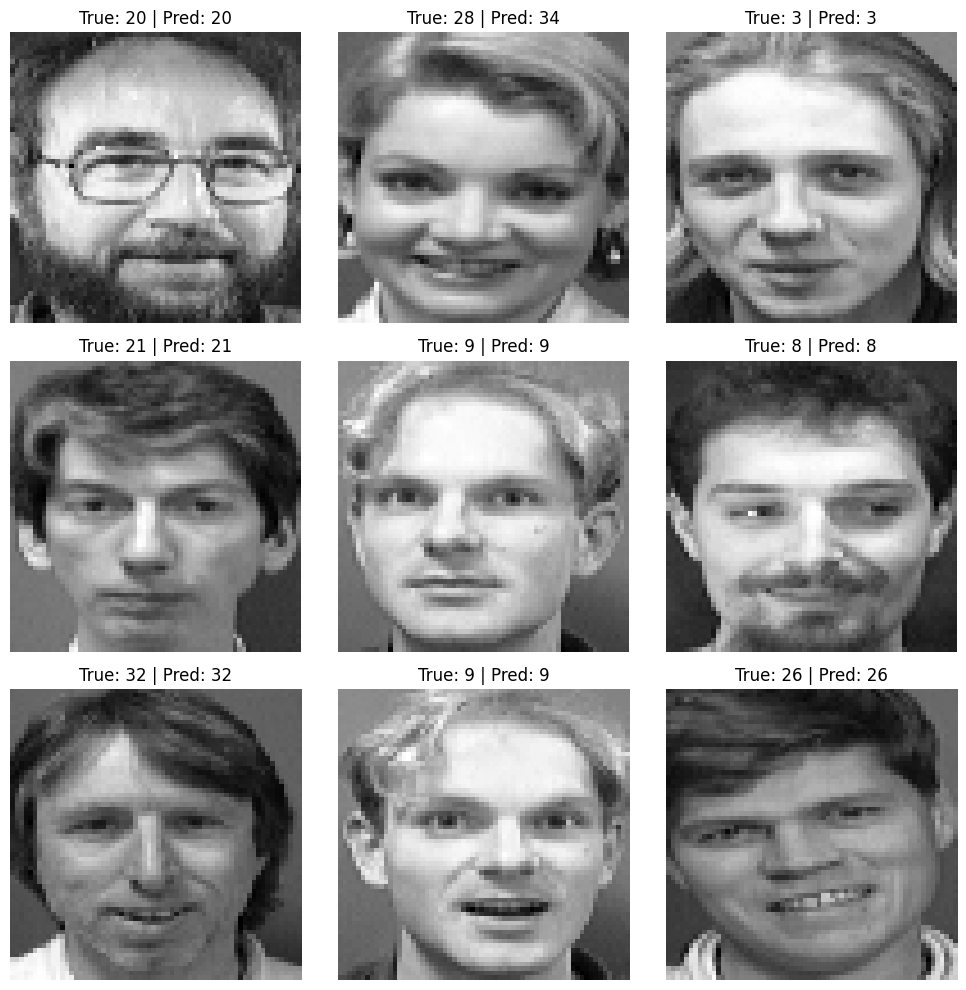

In [12]:
plot_results(X_test[:12], y_test[:12], y_pred[:12])